<a href="https://colab.research.google.com/github/DeviShree2006/ITA0620/blob/main/Decision_Tree_for_fraud_detection_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

E-Commerce Fraud Detection Dataset:
  TransactionAmt ForeignIP CardPresent Fraud
0           High       Yes          No   Yes
1           High       Yes         Yes    No
2            Low       Yes          No    No
3           High        No          No    No
4           High       Yes          No   Yes
5            Low        No         Yes    No
6           High       Yes          No   Yes
7            Low       Yes          No    No

Encoded Features:
   TransactionAmt_High  TransactionAmt_Low  ForeignIP_No  ForeignIP_Yes  \
0                    1                   0             0              1   
1                    1                   0             0              1   
2                    0                   1             0              1   
3                    1                   0             1              0   
4                    1                   0             0              1   
5                    0                   1             1              0   
6              

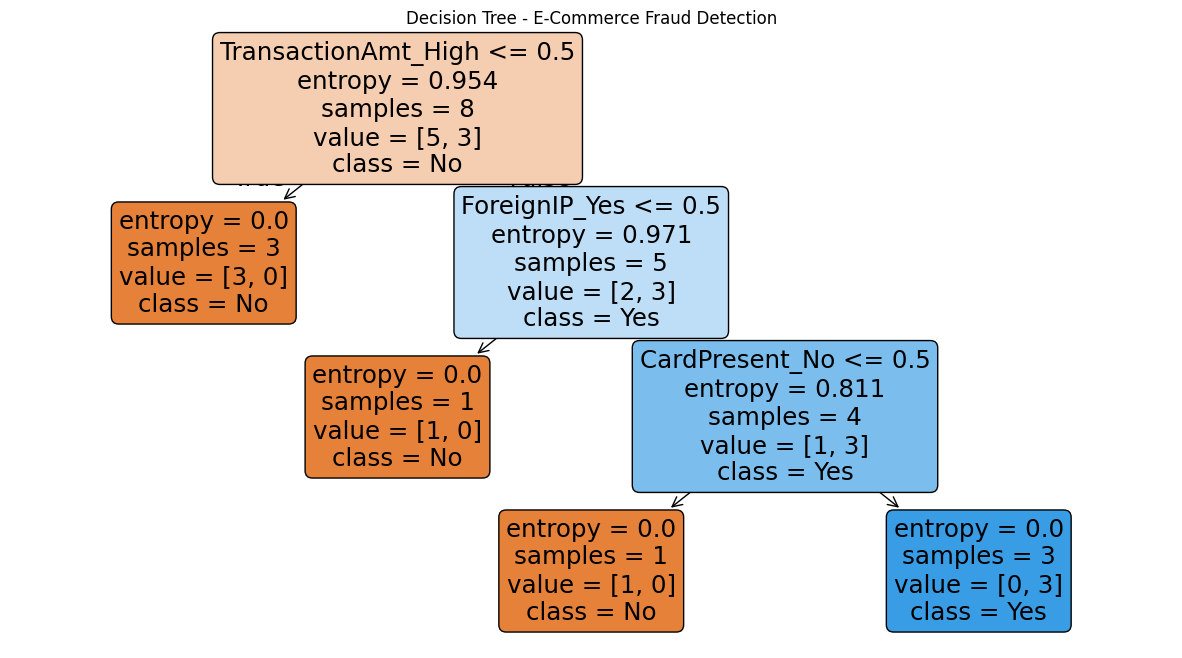


New Transaction Prediction:
Warning! Transaction is FRAUDULENT.


In [1]:
# Decision Tree Classification
# E-Commerce Fraud Detection

import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

# Step 1: Create the dataset

data = {
    'TransactionAmt': ['High', 'High', 'Low', 'High',
                       'High', 'Low', 'High', 'Low'],

    'ForeignIP': ['Yes', 'Yes', 'Yes', 'No',
                  'Yes', 'No', 'Yes', 'Yes'],

    'CardPresent': ['No', 'Yes', 'No', 'No',
                    'No', 'Yes', 'No', 'No'],

    'Fraud': ['Yes', 'No', 'No', 'No',
              'Yes', 'No', 'Yes', 'No']
}

df = pd.DataFrame(data)

print("E-Commerce Fraud Detection Dataset:")
print(df)


# Step 2: Separate input features and target

X = df[['TransactionAmt', 'ForeignIP', 'CardPresent']]
y = df['Fraud']


# Step 3: Convert categorical values into numerical values

X = pd.get_dummies(X, dtype=int)

print("\nEncoded Features:")
print(X)


# Step 4: Create the Decision Tree Classifier

model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)


# Step 5: Train the model

model.fit(X, y)


# Step 6: Predict the training dataset

predictions = model.predict(X)

print("\nActual Values:")
print(list(y))

print("\nPredicted Values:")
print(list(predictions))


# Step 7: Calculate accuracy

accuracy = model.score(X, y)

print("\nModel Accuracy:", accuracy * 100, "%")


# Step 8: Visualize the Decision Tree

plt.figure(figsize=(15, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True
)

plt.title("Decision Tree - E-Commerce Fraud Detection")

plt.show()


# Step 9: Predict a new transaction

new_transaction = pd.DataFrame({
    'TransactionAmt': ['High'],
    'ForeignIP': ['Yes'],
    'CardPresent': ['No']
})

new_transaction = pd.get_dummies(new_transaction, dtype=int)

new_transaction = new_transaction.reindex(
    columns=X.columns,
    fill_value=0
)

result = model.predict(new_transaction)

print("\nNew Transaction Prediction:")

if result[0] == 'Yes':
    print("Warning! Transaction is FRAUDULENT.")
else:
    print("Transaction is NOT FRAUDULENT.")